In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from scipy.optimize import fsolve
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

## Modèle de volatilité stochastique d'Heston

Implémentons le modèle de volatilité stochastique d'Heston. Voici ce que l'on doit coder : 
\begin{equation}
    dv_t = \kappa(\theta - v_t)dt + \xi \sqrt{v_t} dW_t
\end{equation}

On approxime la variation $dv_t$ par : 

$dv_t \approx v_{t+1} - v_t$

Où : 

* $v_t$ est la variance à l'instant $t$.
* $\kappa$ est la vitesse de retour à la moyenne.
* $\theta$ est la variance moyenne à long terme.
* $\xi$ est la volatilité de la volatilité (Vol of Vol).
* $Z_t \sim \mathcal{N}(0,1)$ est une variable aléatoire normale centrée réduite.

In [2]:
def Heston_vol(var0, kappa, teta, xi, T, N):
    #var0 est la volatilité du sous-jacent au carré à t = 0
    
    dt = T/N
    var = np.zeros(N+1)
    var[0] = var0
    
    for i in range(1, N+1):
        dWt = np.random.randn()
        var[i] = var[i-1] + kappa*(teta - var[i-1])*dt +xi*np.sqrt(var[i-1])*np.sqrt(dt)*dWt
    
    return(np.sqrt(var))

Représentation de la volatilité en fonction du temps

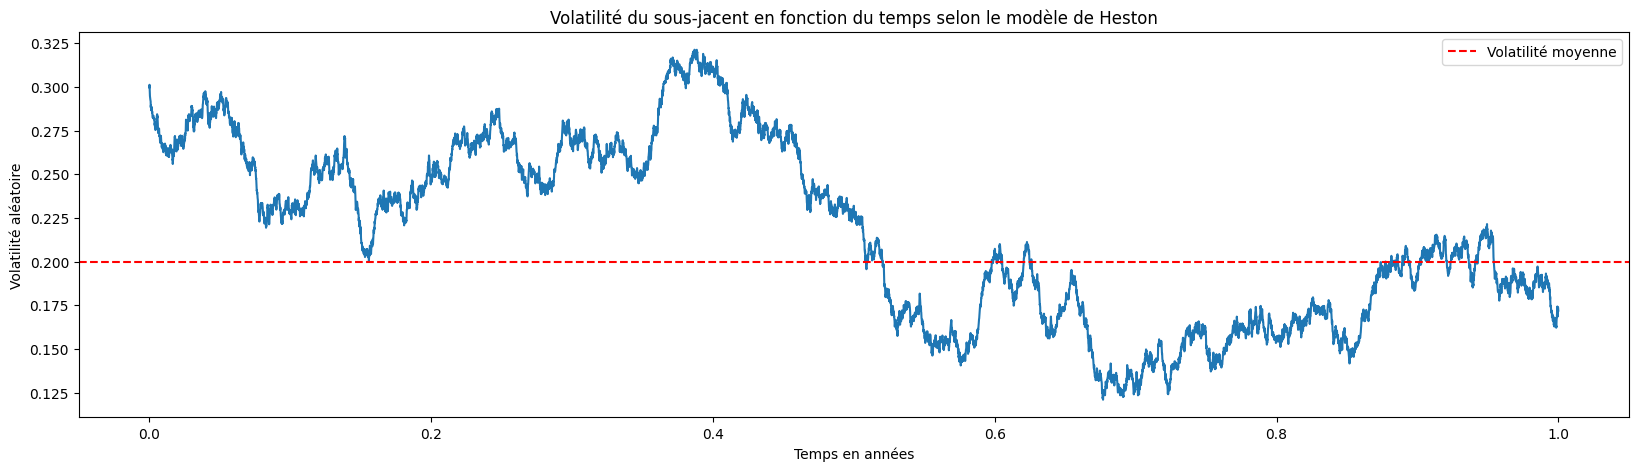

In [3]:
#Paramètres
var0 = 0.09
kappa = 2
teta = 0.04
xi = 0.3
T = 1
N = 10000   

vol_heston = Heston_vol(var0, kappa, teta, xi, T, N)
t = np.linspace(0, T, len(vol_heston))

plt.figure(figsize=(20, 5))
plt.plot(t, vol_heston)
plt.axhline(y = np.sqrt(teta), color='r', linestyle='--', label='Volatilité moyenne')
plt.xlabel("Temps en années")
plt.ylabel("Volatilité aléatoire")
plt.title("Volatilité du sous-jacent en fonction du temps selon le modèle de Heston")
plt.legend(loc = 'best')
plt.show()

Maintenant implémontons le modele d'Heston avec la methode de Monte-Carlo pour pricer un call.

Le modèle suppose que le prix de l'actif $S_t$ et sa variance $v_t$ suivent les processus suivants :

$$
\begin{cases}
\frac{dS_t}{S_t} = r dt + \sqrt{v_t} dW_t^S & \text{(Dynamique du Prix)} \\
dv_t = \kappa(\theta - v_t)dt + \xi \sqrt{v_t} dW_t^v & \text{(Dynamique de la Variance)}
\end{cases}
$$

Paramètres
* **$r$** : Taux sans risque.
* **$\kappa$** (Kappa) : Vitesse de retour à la moyenne de la variance.
* **$\theta$** (Theta) : Variance moyenne à long terme.
* **$\xi$** (Xi) : Volatilité de la volatilité ("Vol of Vol").
* **$\rho$** (Rho) : Corrélation entre les deux mouvements browniens. Sa valeur dépend fortement de la classe d'actif du sous-jacent. Pour les actions et les indices boursiers, $\rho$ est généralement fortement négatif (autour de -0.6 à -0.8). Cela s'explique par "l'effet de levier" : une chute violente des cours s'accompagne d'un mouvement de panique, ce qui fait exploser la volatilité (les deux varient donc en sens inverse).

Pour la simulation Monte Carlo, on construit ces mouvements à partir de deux variables normales centrées réduites indépendantes $Z_1$ et $Z_2$ ($\sim \mathcal{N}(0,1)$) :

$$
\begin{aligned}
dW_t^v &= Z_1 \sqrt{dt} \\
dW_t^S &= \left( \rho Z_1 + \sqrt{1 - \rho^2} Z_2 \right) \sqrt{dt}
\end{aligned}
$$

In [4]:
def Monte_carlo_pricer_heston(S0, K, r, T, var0, kappa, teta, xi, rho, N, nb_simu, option_type='call'):
    dt = T / N
    
    # Initialisation de la variance
    var = np.zeros((N+1, nb_simu))
    var[0, :] = var0
    
    # N tirages 
    Z1 = np.random.randn(N, nb_simu)
    Z2 = np.random.randn(N, nb_simu)
    
    # Mouvements browniens corrélés
    dWt_var = np.sqrt(dt) * Z1
    dWt_price = (rho * Z1 + np.sqrt(1 - rho**2) * Z2) * np.sqrt(dt)
    
    for i in range(1, N+1):
        var_positive = np.maximum(var[i-1, :], 0) # Assurer que la variance reste positive
        var[i, :] = var[i-1, :] + kappa * (teta - var_positive) * dt + xi * np.sqrt(var_positive) * dWt_var[i-1, :]
    
    # On prend bien que des variances positives pour le calcul du prix
    # Et on prend toutes les lignes sauf la dernière car on veut une matrice de même taille que dWt_price
    var_positive_path = np.maximum(var[:-1, :], 0) 
    dG = (r - 0.5 * var_positive_path) * dt + np.sqrt(var_positive_path) * dWt_price
    
    # Somme des accroissements sur les N étapes
    variation = np.sum(dG, axis=0)
    S = S0 * np.exp(variation)
    
    # Calcul du payoff selon le type d'option
    option_type = option_type.lower()
    if option_type == 'call':
        pay_off = np.maximum(S - K, 0)
    elif option_type == 'put':
        pay_off = np.maximum(K - S, 0)
        
    # Espérance et actualisation
    pay_off_mean = np.mean(pay_off)
    price = pay_off_mean * np.exp(-r * T)
    
    return price

In [5]:
def Monte_carlo_pricer(S0, K, sigma, r, T, N, nb_simu, option_type='call'):
    dt = T / N
    
    # Simulation des trajectoires
    epsilon = np.random.randn(N, nb_simu)
    dz = epsilon * np.sqrt(dt)
    dG = (r - (sigma**2)/2) * dt + sigma * dz
    
    variation = np.sum(dG, axis=0)
    St = S0 * np.exp(variation)
    
    # Calcul du payoff selon le type d'option
    option_type = option_type.lower() # Sécurité pour gérer 'Call' ou 'CALL'
    if option_type == 'call':
        pay_off = np.maximum(St - K, 0)
    elif option_type == 'put':
        pay_off = np.maximum(K - St, 0)
        
    # Espérance du payoff
    pay_off_mean = np.mean(pay_off)
    
    # Actualisation du prix de l'option
    price = pay_off_mean * np.exp(-r * T)
    
    return price

Comparaison des prix des options en fonction de la volatilité constante ou stochastique. 

In [ ]:
#Paramètres
S0 = 100
K = 115
r = 0.05
var0 = 0.09
sigma0 = np.sqrt(var0)
kappa = 2    
teta = 0.09
moy_sigma = np.sqrt(teta)
xi = 0.3
rho = -0.7    # paramètre de corrélation entre les deux processus stochastiques, pour une action                 
T = 1
N = 1000 
nb_simu = 100000
option_type = 'call'

#Comparaison des prix des calls en fonction des modèles

prix1 = Monte_carlo_pricer_heston(S0, K, r, T, var0, kappa, teta, xi, rho, N, nb_simu)
prix2 = Monte_carlo_pricer(S0, K, sigma0, r, T, N, nb_simu, option_type)

diff = abs(prix1 - prix2) / prix1 * 100

print("le prix du call avec une simulation de Monte-Carlo couplé avec le modèle d'Heston pour la volatilité est de : ", prix1)
print("le prix du call avec une simulation de Monte-Carlo couplé avec une volatilité constante est de : ", prix2)
print("La différence est de : ", diff, "%")


le prix du call avec une simulation de Monte-Carlo couplé avec le modèle d'Heston pour la volatilité est de :  7.69047022659878
le prix du call avec une simulation de Monte-Carlo couplé avec une volatilité constante est de :  8.364337177962136
La différence est de :  8.762363438228714 %


Cette différence s'explique par la corrélation négative (ρ=−0.7) : contrairement à Black-Scholes, Heston modélise le fait que la hausse du prix écrase la volatilité. Cela veut dire que la probabilité que la Call finisse dans la monnaie est plus faible, ce qui le rend moins cher.

## Calcul du prix d'une option à n'importe quel temps T avec le modèle d'Heston

L'évaluation du prix des options dans le modèle de volatilité stochastique de Heston est rendue possible grâce aux propriétés de la **Transformée de Fourier**, qui permet de passer par la **fonction caractéristique** du processus.

### Prix du Call et du Put

Le prix du **Call européen** $C$ est donné par :

$$C = S_0 \, e^{-q\tau} P_1 - K \, e^{-r\tau} P_2$$

Le prix du **Put européen** $P$ se déduit directement par la **parité Call-Put** :

$$P = C - S_0 \, e^{-q\tau} + K \, e^{-r\tau}$$

### Les probabilités $P_1$ et $P_2$

Les termes $P_j$ (pour $j \in \{1, 2\}$) sont évalués via l'**inversion de Fourier** :

$$P_j = \frac{1}{2} + \frac{1}{\pi}
        \int_0^{+\infty}
        \Re\!\left(\frac{e^{-iu\ln(K)}\,\phi_j(u)}{iu}\right) du$$

### La fonction caractéristique $\phi_j(u)$

La fonction caractéristique $\phi_j(u)$ s'écrit :

$$\phi_j(u) = \exp\!\Big(
  iu\bigl(\ln(S_0) + (r - q)\tau\bigr)
  + C_j(u,\tau)\,\theta
  + D_j(u,\tau)\,v_0
\Big)$$

avec les paramètres du modèle :

| Paramètre | Description |
|-----------|-------------|
| $S_0$     | Prix spot initial |
| $v_0$     | Variance initiale |
| $\theta$  | Variance long terme |
| $\kappa$  | Vitesse de retour à la moyenne |
| $\xi$     | Volatilité de la volatilité (vol of vol) |
| $\rho$    | Corrélation entre les deux browniens |
| $r, q$    | Taux sans risque et taux de dividende |
| $\tau$    | Maturité (en années) |
| $K$       | Strike |

### Variables intermédiaires pour $C_j$ et $D_j$

**Constantes selon $j$**

- Pour $j = 1$ :

$$u_1 = \frac{1}{2}, \qquad b_1 = \kappa - \rho\xi$$

- Pour $j = 2$ :

$$u_2 = -\frac{1}{2}, \qquad b_2 = \kappa$$

---

**Calcul de $d_j$**

$$d_j = \sqrt{\left(\rho\xi\, iu - b_j\right)^2 - \xi^2\left(2u_j\, iu - u^2\right)}$$

**Calcul de $g_j$**

$$g_j = \frac{b_j - \rho\xi\, iu + d_j}{b_j - \rho\xi\, iu - d_j}$$

---

**Termes finaux $D_j$ et $C_j$**

$$D_j(u,\tau) = \frac{b_j - \rho\xi\, iu - d_j}{\xi^2}
               \left[\frac{1 - e^{-d_j \tau}}{1 - g_j \, e^{-d_j \tau}}\right]$$

$$C_j(u,\tau) = \frac{\kappa}{\xi^2}
               \left[
                 \left(b_j - \rho\xi\, iu - d_j\right)\tau
                 - 2\ln\!\left(\frac{1 - g_j \, e^{-d_j \tau}}{1 - g_j}\right)
               \right]$$

In [13]:
def fonction_a_integrer1(u, K, S0, r, q, tau, var0, kappa, theta, xi, rho):
    u1 = 1/2
    b1 = kappa - rho*xi
    
    if u < 1e-10: 
        u = 1e-10
    
    d1 = np.sqrt((rho*xi*1j*u-b1)**2 - (xi**2)*(2*u1*1j*u - u**2))
    
    g1 = (b1 - rho*xi*1j*u - d1)/(b1 - rho*xi*1j*u + d1)
    
    D1 = (b1 - rho*xi*1j*u - d1)/(xi**2) * (1 - np.exp(-d1*tau))/(1 - g1*np.exp(-d1*tau))
    C1 = kappa*((b1 - rho*xi*1j*u - d1)*tau - 2*np.log((1 - g1*np.exp(-d1*tau))/(1 - g1)))/(xi**2)
    
    ph1 = np.exp(1j*u*(np.log(S0) + (r - q)*tau) + C1*theta + D1*var0)
    
    integrante1 = (np.exp(-1j*u*np.log(K))*ph1)/(1j*u)

    return(integrante1.real)

def fonction_a_integrer2(u, K, S0, r, q, tau, var0, kappa, theta, xi, rho):
    u2 = -1/2
    b2 = kappa
    
    if u < 1e-10: 
        u = 1e-10
    
    d2 = np.sqrt((rho*xi*1j*u-b2)**2 - (xi**2)*(2*u2*1j*u - u**2))
    
    g2 = (b2 - rho*xi*1j*u - d2)/(b2 - rho*xi*1j*u + d2)
    
    D2 = (b2 - rho*xi*1j*u - d2)/(xi**2) * (1 - np.exp(-d2*tau))/(1 - g2*np.exp(-d2*tau))
    C2 = kappa*((b2 - rho*xi*1j*u - d2)*tau - 2*np.log((1 - g2*np.exp(-d2*tau))/(1 - g2)))/(xi**2)
    
    ph2 = np.exp(1j*u*(np.log(S0) + (r - q)*tau) + C2*theta + D2*var0)
    
    integrante2 = (np.exp(-1j*u*np.log(K))*ph2)/(1j*u)
    
    return(integrante2.real)

def pricing_Heston_Fourier(K, S0, r, q, T, var0, kappa, theta, xi, rho, N, option_type):
    dt = T/N
    
    price_call = np.zeros(N)
    price_option = np.zeros(N)
    
    for i in range (N):
        tau = T - i*dt
        
        if tau <= 1e-6:
            price_option[i] = max(0, S0 - K) if option_type == 'call' else max(0, K - S0)
            continue
        
        integrale1 = quad(fonction_a_integrer1, 0, 100, args =  (K, S0, r, q, tau, var0, kappa, theta, xi, rho))
        integrale2 = quad(fonction_a_integrer2, 0, 100, args =  (K, S0, r, q, tau, var0, kappa, theta, xi, rho))
    
        P1 = 0.5 + (1/(np.pi))*integrale1[0]
        P2 = 0.5 + (1/(np.pi))*integrale2[0]

        price_call[i] = S0*np.exp(-q*tau)*P1 - K*np.exp(-r*tau)*P2
        
        if option_type == "call":
            price_option[i] = price_call[i]
        else :
            price_option[i] = price_call[i] - S0*np.exp(-q*tau) + K*np.exp(-r*tau)
    
    return(price_option)

Représentation du prix d'une opion en fonction de la maturité

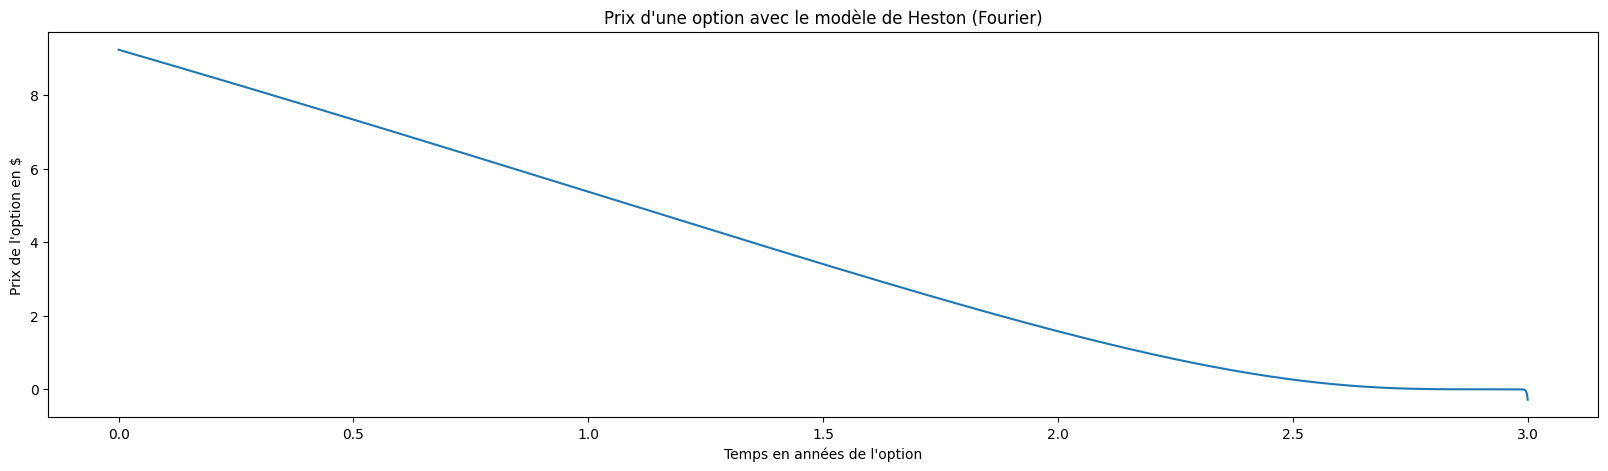

In [14]:
#Paramètres 
S0 = 100
K = 145
r = 0.05
q = 0.02
T = 3
N = 10000
var0 = 0.09
kappa = 2
theta = 0.09
xi = 0.3
rho = -0.5
option_type = 'call'

price = pricing_Heston_Fourier(K, S0, r, q, T, var0, kappa, theta, xi, rho, N, option_type)
t = np.linspace(0, T, len(price))

plt.figure(figsize=(20, 5))
plt.plot(t, price)
plt.xlabel("Temps en années de l'option")
plt.ylabel("Prix de l'option en $")
plt.title("Prix d'une option avec le modèle de Heston (Fourier)")
plt.show()

### Volatilité implicite du sous jacent

En inversant la formule de Black-Scholes nous pouvons trouver la volatilité implicite du sous-jacent.

In [21]:
def BS(S, K, sigma, r, q, T, option_type):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    
    if option_type == 'call':
        option_price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        option_price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    return(option_price)

def implied_vol_strike(S0, K, q, r, T, var0, kappa, theta, xi, rho, option_type):
    iv = np.zeros(len(K))
    for i in range (len(K)):
        price_heston = pricing_Heston_Fourier(K[i], S0, r, q, T, var0, kappa, theta, xi, rho, 1, option_type)[0]
        
        def fonction(sigma):
            return (BS(S0, K[i], sigma, r, q, T, option_type) - price_heston)
        
        iv0 = iv[i-1] if i > 0 else np.sqrt(var0)
        iv[i] = fsolve(fonction, iv0, maxfev=5000)[0]
        
    return(iv)

Représentation de la volatilité implicite en fonction des strikes

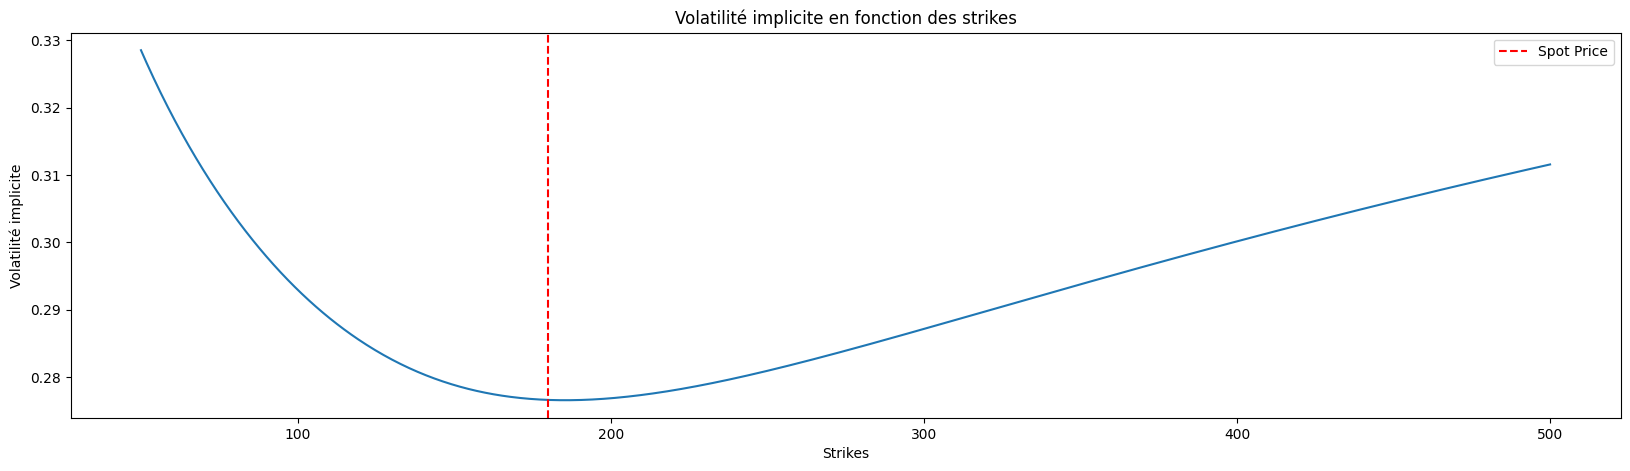

In [32]:
#Paramètres 
S0 = 180
r = 0.05
q = 0.02
T = 1
N = 10000
var0 = 0.09
kappa = 2
theta = 0.07
xi = 0.3
rho = 0
option_type = 'call'

K = np.linspace(50, 500, 1000)
vol = implied_vol_strike(S0, K, q, r, T, var0, kappa, theta, xi, rho, option_type)

plt.figure(figsize=(20, 5))
plt.plot(K, vol)
plt.xlabel("Strikes")
plt.ylabel("Volatilité implicite")
plt.title("Volatilité implicite en fonction des strikes")
plt.axvline(x = S0, color='r', linestyle='--', label='Spot Price')
plt.legend(loc = "best")
plt.show()

On observe bien le smile de volatilité. 

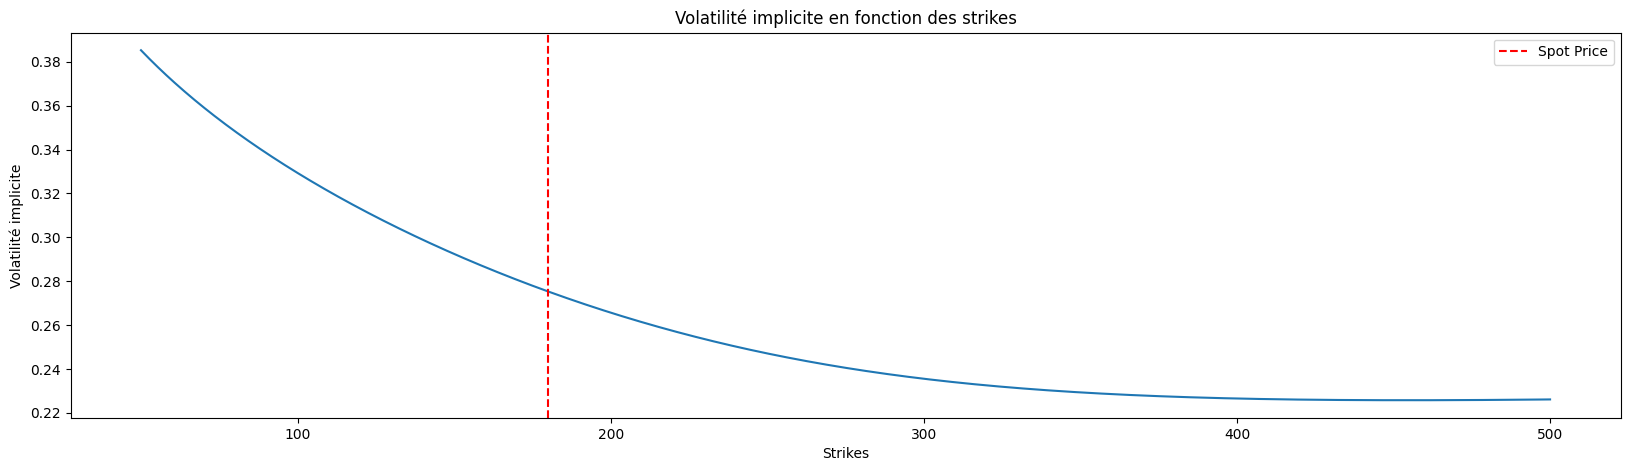

In [33]:
#Paramètres 
S0 = 180
r = 0.05
q = 0.02
T = 1
N = 10000
var0 = 0.09
kappa = 2
theta = 0.07
xi = 0.3
rho = -0.6
option_type = 'call'

K = np.linspace(50, 500, 1000)
vol = implied_vol_strike(S0, K, q, r, T, var0, kappa, theta, xi, rho, option_type)

plt.figure(figsize=(20, 5))
plt.plot(K, vol)
plt.xlabel("Strikes")
plt.ylabel("Volatilité implicite")
plt.title("Volatilité implicite en fonction des strikes")
plt.axvline(x = S0, color='r', linestyle='--', label='Spot Price')
plt.legend(loc = "best")
plt.show()

Ici avec $\rho = -0.6$, qui représente la corrélation entre la variance et le prix du sous-jacent sur le marché actions, on peut observer le skew.  

### La nappe de volatilité implicite

In [34]:
def nappe_vol_3D(S0, K, q, r, T, var0, kappa, theta, xi, rho, option_type):
    nappe = np.zeros((len(T), len(K)))
    
    for i in range (len(T)):
        #Pour chaque T je calcule les prix avec tout les strikes
        
        for j in range (len(K)):
            price_heston = pricing_Heston_Fourier(K[j], S0, r, q, T[i], var0, kappa, theta, xi, rho, 1, option_type)[0]
        
            def fonction(sigma):
                return (BS(S0, K[j], sigma, r, q, T[i], option_type) - price_heston)
            
            nappe[i, j] = fsolve(fonction, np.sqrt(var0), maxfev=5000)[0]
        
    return(nappe)

Représentation de la nappe de volatilité implicite 

/var/folders/nz/_b1djzmn6ml2kmfl6gfmb32w0000gn/T/ipykernel_51477/3824806886.py:13: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  nappe[i, j] = fsolve(fonction, np.sqrt(var0), maxfev=5000)[0]


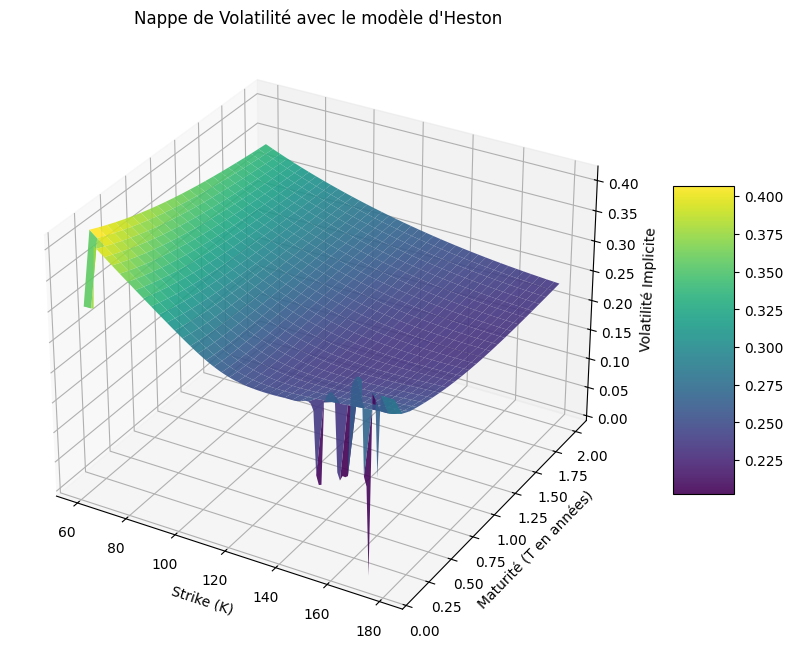

In [43]:
#Paramètres 
S0 = 100
r = 0.05
q = 0.02
N = 10000
var0 = 0.09
kappa = 2
theta = 0.09
xi = 0.6
rho = -0.6
option_type = 'call'

T = np.linspace(0.1, 2, 24)
K = np.linspace(60, 180, 120)
vol = nappe_vol_3D(S0, K, q, r, T, var0, kappa, theta, xi, rho, option_type)

K_grid, T_grid = np.meshgrid(K, T)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# On trace la surface
surf = ax.plot_surface(K_grid, T_grid, vol, cmap=cm.viridis, edgecolor='none', alpha=0.9)

# Labels et design
ax.set_xlabel('Strike (K)')
ax.set_ylabel('Maturité (T en années)')
ax.set_zlabel('Volatilité Implicite')
ax.set_title("Nappe de Volatilité avec le modèle d'Heston")

# Ajout d'une barre de couleur
fig.colorbar(surf, shrink=0.5, aspect=5)

# Orientation du graphique pour mieux voir le Skew
ax.view_init(elev=30, azim=300)

plt.show()

Ici, avec $\rho =−0,6$, on observe bien le skew sur la nappe de volatilité implicite : les puts deep OTM affichent une volatilité implicite plus élevée que les calls deep OTM.